# 23_Preprocess: 4 kỹ thuật xử lý ảnh (affine, Gray-World, khử nhiễu thích nghi cục bộ, CLAHE)
- Chạy trên ảnh khung hình, TRƯỚC MediaPipe. Thứ tự (chốt 08/11/2026): affine -> Gray-World -> khử nhiễu -> CLAHE.
- Affine: dùng landmark khung trước để xoay/scale/cắt vùng tay thành ảnh 256x256, 3 bước sau chạy trên ảnh cắt (nhanh hơn nhiều so với khung 1080p), rồi chạy MediaPipe và đổi landmark về tọa độ gốc.
- Notebook này định nghĩa, kiểm tra và minh họa. Ghép vào trích landmark và thí nghiệm bật/tắt (mục 5) làm ở bước sau.

In [1]:
#cell 1: cấu hình đường dẫn và lấy 3 khung mẫu (1 khung giữa video của mỗi nguồn) để thử 4 kỹ thuật
import cv2, numpy as np, time
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path(r"C:\Users\Acer Nitro 5 Tiger\Downloads\Data_321")
OUT = BASE / "preprocess_demo"; OUT.mkdir(exist_ok=True)
exts = {".mp4", ".mov", ".avi", ".mkv"}

samples = {}
for src in ["Dataset_hand", "dataset_labeled", "Dataset_bonus"]:
    p = next(q for q in sorted((BASE / src).rglob("*")) if q.suffix.lower() in exts)
    cap = cv2.VideoCapture(str(p)); cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2)
    ok, fr = cap.read(); cap.release(); assert ok, p
    samples[src] = fr
    print(src, "|", p.name, "| kích thước", fr.shape[1], "x", fr.shape[0])

Dataset_hand | VID_20261002074120297.mp4 | kích thước 1920 x 1080
dataset_labeled | IMG_0510(1)_003.mp4 | kích thước 1920 x 1080
Dataset_bonus | VID_20261024172018538.mp4 | kích thước 1920 x 1080


In [2]:
#cell 2: định nghĩa 4 kỹ thuật xử lý ảnh (ảnh BGR uint8). Thứ tự dùng: affine (cắt ảnh quanh tay) -> Gray-World -> khử nhiễu -> CLAHE trên ảnh cắt
def gray_world(img):
    # cân bằng trắng: nhân mỗi kênh với m / m_k (m = trung bình 3 kênh, m_k = trung bình kênh k)
    x = img.astype(np.float32)
    mk = x.reshape(-1, 3).mean(0)
    return np.clip(x * (mk.mean() / mk), 0, 255).astype(np.uint8)

def lee_denoise(img, win=5):
    # khử nhiễu thích nghi cục bộ (bộ lọc Lee): out = mean + k * (x - mean), k = var / (var + var_nhiễu)
    # var, mean tính trong cửa sổ win x win; var_nhiễu = trung vị của var cục bộ (ước lượng từ vùng phẳng)
    x = img.astype(np.float32)
    m = cv2.blur(x, (win, win))
    v = np.maximum(cv2.blur(x * x, (win, win)) - m * m, 0)
    vn = np.median(v[::4, ::4].reshape(-1, 3), axis=0)
    k = v / (v + vn + 1e-6)
    return np.clip(m + k * (x - m), 0, 255).astype(np.uint8)

def clahe_lab(img, clip=2.0, tile=8):
    # tăng tương phản cục bộ: CLAHE trên kênh L của ảnh LAB, giữ nguyên màu (kênh a, b)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    lab[:, :, 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

def affine_matrix(lm, W, H, S=256, factor=3.5):
    # ma trận affine 2x3 (ảnh gốc -> ảnh cắt SxS): xoay để cổ tay (0) -> khớp 9 hướng lên trên, scale để cạnh cắt = factor x độ dài cổ tay-khớp 9, tâm là trung điểm hai điểm đó
    p0 = lm[0, :2] * (W, H); p9 = lm[9, :2] * (W, H); v = p9 - p0
    d = np.hypot(*v); c = (p0 + p9) / 2
    ang = 90 - np.degrees(np.arctan2(-v[1], v[0]))      # góc xoay ngược chiều kim đồng hồ (độ)
    M = cv2.getRotationMatrix2D((float(c[0]), float(c[1])), float(ang), S / (factor * d))
    M[0, 2] += S / 2 - c[0]; M[1, 2] += S / 2 - c[1]
    return M

def affine_warp(img, M, S=256):
    return cv2.warpAffine(img, M, (S, S), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)

def affine_back(lm_crop, M, W, H, S=256):
    # đổi landmark (x, y, z chuẩn hóa trên ảnh cắt) về tọa độ ảnh gốc bằng ma trận nghịch đảo; z đổi tỉ lệ theo S / (scale x W)
    Mi = cv2.invertAffineTransform(M); scale = np.hypot(M[0, 0], M[0, 1])
    pts = np.c_[lm_crop[:, 0] * S, lm_crop[:, 1] * S, np.ones(len(lm_crop))] @ Mi.T
    return np.c_[pts[:, 0] / W, pts[:, 1] / H, lm_crop[:, 2] * S / (scale * W)]

def preprocess_crop(crop):
    # 3 bước chạy trên ảnh cắt SxS (sau affine): Gray-World -> khử nhiễu -> CLAHE
    return clahe_lab(lee_denoise(gray_world(crop)))

print("Đã định nghĩa: gray_world, lee_denoise, clahe_lab, affine_matrix, affine_warp, affine_back, preprocess_crop")

Đã định nghĩa: gray_world, lee_denoise, clahe_lab, affine_matrix, affine_warp, affine_back, preprocess_crop


In [3]:
#cell 3: kiểm tra từng kỹ thuật trên dữ liệu có đáp án biết trước (chưa cần MediaPipe)
rng = np.random.default_rng(0)

# Gray-World: ảnh lệch màu -> sau xử lý trung bình 3 kênh phải bằng nhau
a = np.clip(rng.normal(120, 30, (200, 200, 3)) * (0.6, 1.0, 1.4), 0, 255).astype(np.uint8)
print("Gray-World trung bình kênh trước:", a.reshape(-1, 3).mean(0).round(1), "| sau:", gray_world(a).reshape(-1, 3).mean(0).round(1))

# Khử nhiễu: ảnh có cạnh (60 | 180) cộng nhiễu sigma 10 -> nhiễu vùng phẳng giảm, độ cao cạnh giữ gần 120
b = np.full((200, 200, 3), 60, np.float32); b[:, 100:] = 180
n = np.clip(b + rng.normal(0, 10, b.shape), 0, 255).astype(np.uint8)
f = lee_denoise(n)
print("Lee độ lệch chuẩn vùng phẳng trước:", n[:, 10:80].std().round(2), "| sau:", f[:, 10:80].std().round(2))
print("Lee độ cao cạnh trước:", (n[:, 102:108].mean() - n[:, 92:98].mean()).round(1), "| sau:", (f[:, 102:108].mean() - f[:, 92:98].mean()).round(1))

# CLAHE: ảnh tương phản thấp (110..140) -> độ lệch chuẩn kênh L tăng
c = np.clip(rng.normal(125, 6, (200, 200, 3)), 0, 255).astype(np.uint8)
print("CLAHE độ lệch chuẩn trước:", c.std().round(2), "| sau:", clahe_lab(c).std().round(2))

# Affine: điểm cổ tay (0.5, 0.7) và khớp 9 (0.7, 0.5) trên ảnh 640x480 -> sau biến đổi cổ tay phải ở dưới, khớp 9 ngay phía trên (cùng x)
lm = np.zeros((21, 3)); lm[0] = (0.5, 0.7, 0); lm[9] = (0.7, 0.5, 0)
M = affine_matrix(lm, 640, 480)
q = np.array([[0.5 * 640, 0.7 * 480, 1], [0.7 * 640, 0.5 * 480, 1]]) @ M.T
print("Affine: cổ tay ->", q[0].round(1), "| khớp 9 ->", q[1].round(1), "(mong đợi x bằng nhau, y khớp 9 nhỏ hơn)")
back = affine_back(np.c_[q[:, 0] / 256, q[:, 1] / 256, np.zeros(2)], M, 640, 480)
print("Affine khứ hồi, sai số tối đa:", np.abs(back[:, :2] - lm[[0, 9], :2]).max())

Gray-World trung bình kênh trước: [ 71.5 119.5 167.1] | sau: [118.8 118.5 118.9]
Lee độ lệch chuẩn vùng phẳng trước: 10.04 | sau: 5.52
Lee độ cao cạnh trước: 119.9 | sau: 119.9
CLAHE độ lệch chuẩn trước: 6.01 | sau: 10.72
Affine: cổ tay -> [128.  164.6] | khớp 9 -> [128.   91.4] (mong đợi x bằng nhau, y khớp 9 nhỏ hơn)
Affine khứ hồi, sai số tối đa: 1.1102230246251565e-16


Dataset_hand: sai lệch landmark (ảnh đã xử lý so với ảnh gốc) = 0.025 lần độ dài cổ tay-khớp 9
Dataset_hand: thời gian mỗi khung (ms): affine 0.09, Gray-World 1.11, khử nhiễu 2.98, CLAHE 1.03, tổng 3 bước 4.72
dataset_labeled: sai lệch landmark (ảnh đã xử lý so với ảnh gốc) = 0.013 lần độ dài cổ tay-khớp 9
dataset_labeled: thời gian mỗi khung (ms): affine 0.09, Gray-World 1.15, khử nhiễu 2.5, CLAHE 0.93, tổng 3 bước 4.5
Dataset_bonus: không tìm thấy tay trên ảnh đã xử lý
Dataset_bonus: thời gian mỗi khung (ms): affine 0.07, Gray-World 0.95, khử nhiễu 2.53, CLAHE 0.87, tổng 3 bước 4.51


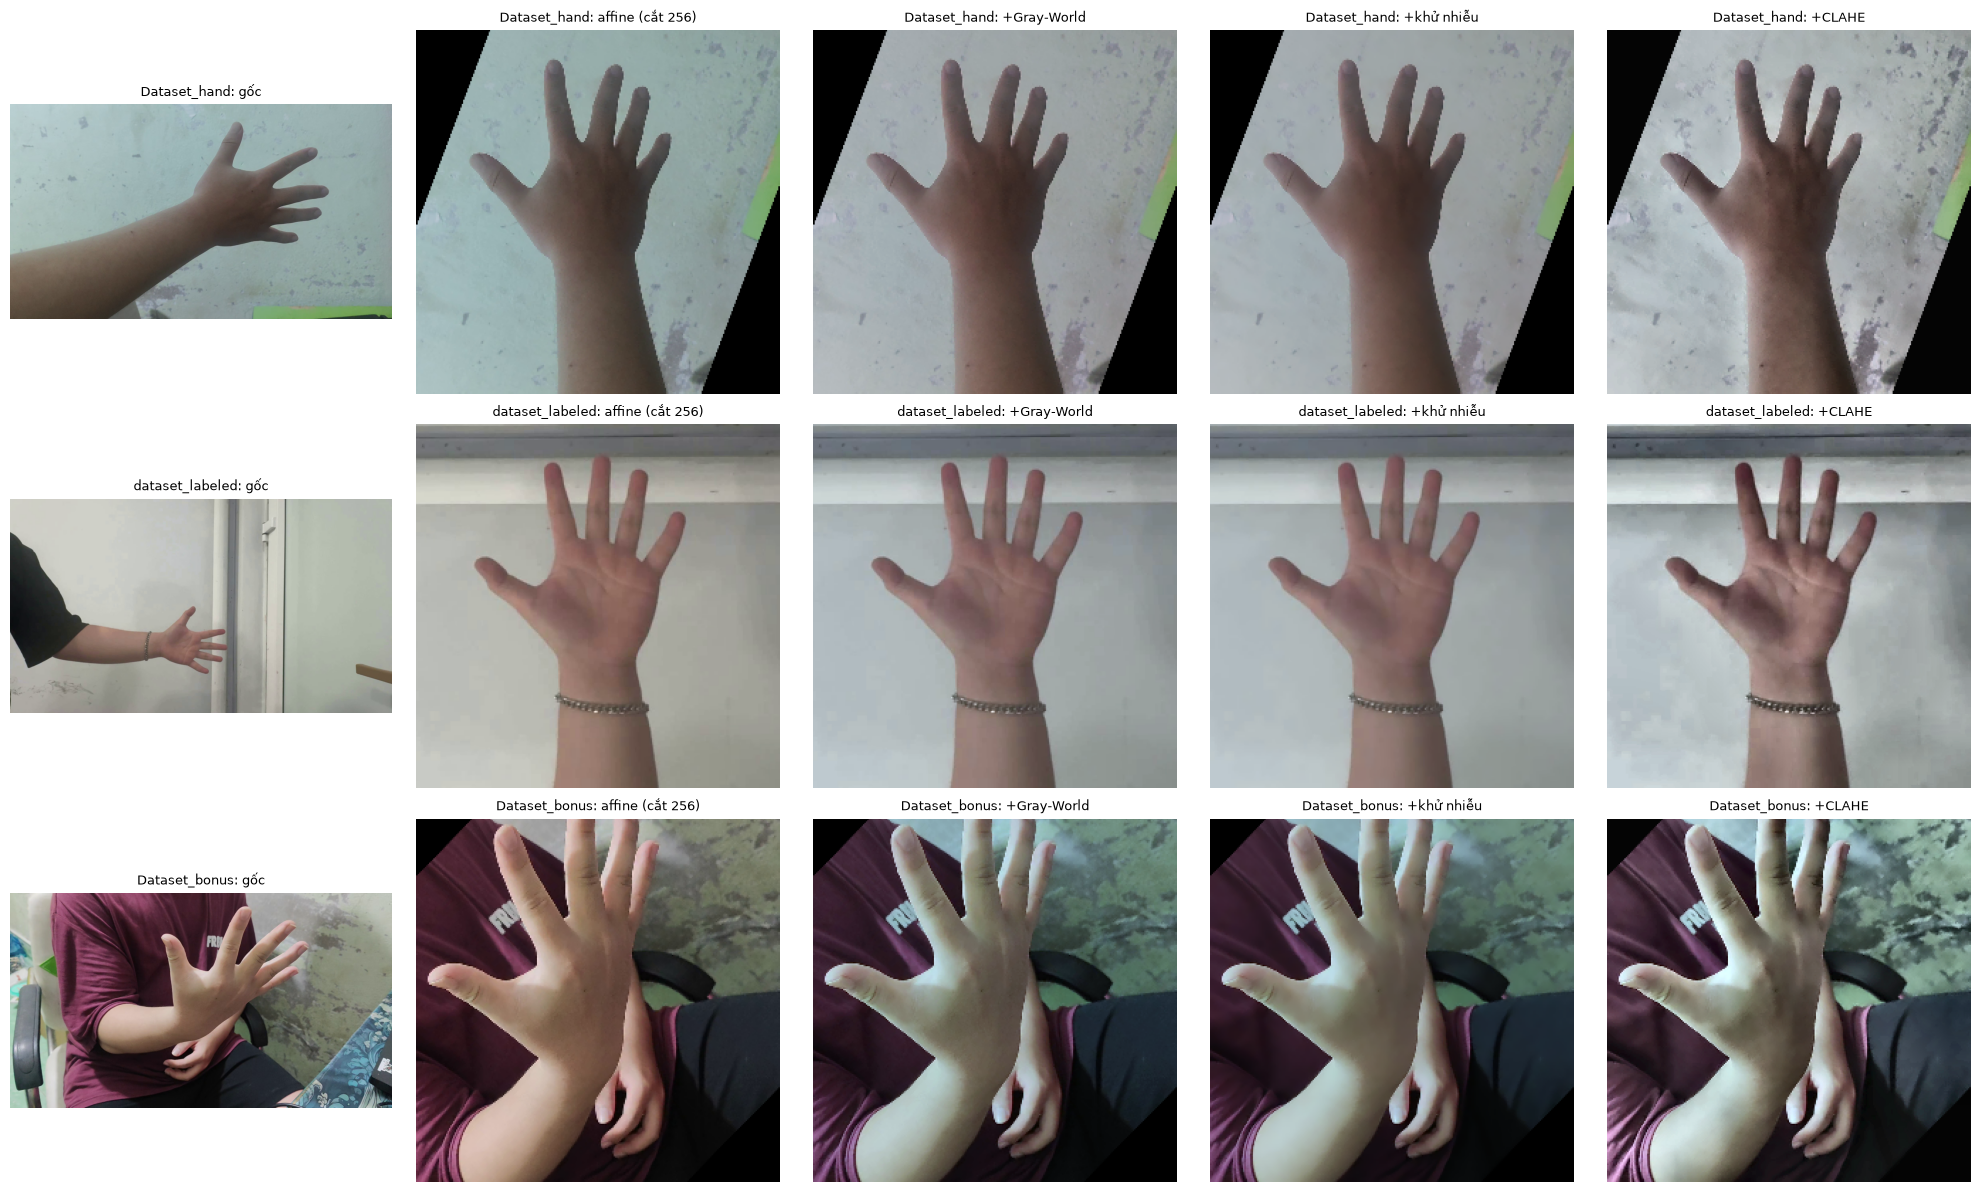

Đã lưu hình: C:\Users\Acer Nitro 5 Tiger\Downloads\Data_321\preprocess_demo\demo_v2.png


In [4]:
#cell 4: thử trên 3 khung mẫu theo thứ tự mới (affine -> Gray-World -> khử nhiễu -> CLAHE trên ảnh cắt 256): vẽ từng bước, đo thời gian, kiểm tra landmark so với ảnh gốc
import mediapipe as mp
from mediapipe.tasks import python as mp_tasks
from mediapipe.tasks.python import vision

det = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
    base_options=mp_tasks.BaseOptions(model_asset_path=str(BASE / "hand_landmarker.task")),
    running_mode=vision.RunningMode.IMAGE, num_hands=1))

def detect(bgr):
    r = det.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)))
    return np.array([[p.x, p.y, p.z] for p in r.hand_landmarks[0]]) if r.hand_landmarks else None

def ms(fn, *a, n=20):
    t = time.perf_counter()
    for _ in range(n): fn(*a)
    return round((time.perf_counter() - t) / n * 1000, 2)

fig, ax = plt.subplots(3, 5, figsize=(20, 12))
for i, (name, fr) in enumerate(samples.items()):
    H, W = fr.shape[:2]
    L0 = detect(fr)                                   # landmark trên ảnh gốc (thay cho landmark khung trước khi chạy thật)
    if L0 is None:
        print(f"{name}: không tìm thấy tay trên ảnh gốc"); continue
    M = affine_matrix(L0, W, H)
    c0 = affine_warp(fr, M); c1 = gray_world(c0); c2 = lee_denoise(c1); c3 = clahe_lab(c2)
    L1 = detect(c3)
    if L1 is not None:
        err = np.linalg.norm((affine_back(L1, M, W, H)[:, :2] - L0[:, :2]) * (W, H), axis=1).mean() / np.hypot(*((L0[9, :2] - L0[0, :2]) * (W, H)))
        print(f"{name}: sai lệch landmark (ảnh đã xử lý so với ảnh gốc) = {err:.3f} lần độ dài cổ tay-khớp 9")
    else: print(f"{name}: không tìm thấy tay trên ảnh đã xử lý")
    for j, (im, t) in enumerate(zip([fr, c0, c1, c2, c3], ["gốc", "affine (cắt 256)", "+Gray-World", "+khử nhiễu", "+CLAHE"])):
        ax[i, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax[i, j].set_title(f"{name}: {t}", fontsize=9); ax[i, j].axis("off")
    print(f"{name}: thời gian mỗi khung (ms): affine {ms(lambda: affine_warp(fr, M))}, Gray-World {ms(gray_world, c0)}, khử nhiễu {ms(lee_denoise, c1)}, CLAHE {ms(clahe_lab, c2)}, tổng 3 bước {ms(preprocess_crop, c0)}")
plt.tight_layout(); plt.savefig(OUT / "demo_v2.png", dpi=80); plt.show()
det.close(); print("Đã lưu hình:", OUT / "demo_v2.png")

In [5]:
#cell 5: Dataset_bonus mất tay ở đâu? Với 20 khung đều của 1 video mỗi nguồn, so 2 trạng thái (chỉ affine / cả 3 bước) và 3 cạnh cắt (3,5 / 4,5 / 5,5 lần độ dài cổ tay-khớp 9)
det = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(   # cell 4 đã đóng detector nên tạo lại
    base_options=mp_tasks.BaseOptions(model_asset_path=str(BASE / "hand_landmarker.task")),
    running_mode=vision.RunningMode.IMAGE, num_hands=1))

def frames_of(p, n=20):
    cap = cv2.VideoCapture(str(p)); tot = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); out = []
    for k in np.linspace(0, tot - 1, n).astype(int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(k)); ok, fr = cap.read()
        if ok: out.append(fr)
    cap.release(); return out

for src in ["Dataset_hand", "dataset_labeled", "Dataset_bonus"]:
    p = next(q for q in sorted((BASE / src).rglob("*")) if q.suffix.lower() in exts)
    frs = frames_of(p); stat = {}; co_tay = 0
    for fr in frs:
        H, W = fr.shape[:2]; L0 = detect(fr)
        if L0 is None: continue
        co_tay += 1; d = np.hypot(*((L0[9, :2] - L0[0, :2]) * (W, H)))
        for f in (3.5, 4.5, 5.5):
            M = affine_matrix(L0, W, H, factor=f); c0 = affine_warp(fr, M)
            for tag, im in (("chỉ affine", c0), ("cả 3 bước", preprocess_crop(c0))):
                L1 = detect(im); s = stat.setdefault((f, tag), [0, []])
                if L1 is not None:
                    s[0] += 1; s[1].append(np.linalg.norm((affine_back(L1, M, W, H)[:, :2] - L0[:, :2]) * (W, H), axis=1).mean() / d)
    print(f"{src} ({p.name}): {co_tay}/{len(frs)} khung có tay trên ảnh gốc")
    for (f, tag), (n, e) in sorted(stat.items()):
        print(f"   cạnh cắt {f} | {tag}: tìm thấy tay {n}/{co_tay} | sai lệch trung bình {np.mean(e):.3f}" if e else f"   cạnh cắt {f} | {tag}: tìm thấy tay {n}/{co_tay}")
det.close()

Dataset_hand (VID_20261002074120297.mp4): 20/20 khung có tay trên ảnh gốc
   cạnh cắt 3.5 | chỉ affine: tìm thấy tay 20/20 | sai lệch trung bình 0.032
   cạnh cắt 3.5 | cả 3 bước: tìm thấy tay 20/20 | sai lệch trung bình 0.031
   cạnh cắt 4.5 | chỉ affine: tìm thấy tay 20/20 | sai lệch trung bình 0.027
   cạnh cắt 4.5 | cả 3 bước: tìm thấy tay 20/20 | sai lệch trung bình 0.028
   cạnh cắt 5.5 | chỉ affine: tìm thấy tay 20/20 | sai lệch trung bình 0.030
   cạnh cắt 5.5 | cả 3 bước: tìm thấy tay 20/20 | sai lệch trung bình 0.029
dataset_labeled (IMG_0510(1)_003.mp4): 20/20 khung có tay trên ảnh gốc
   cạnh cắt 3.5 | chỉ affine: tìm thấy tay 20/20 | sai lệch trung bình 0.011
   cạnh cắt 3.5 | cả 3 bước: tìm thấy tay 20/20 | sai lệch trung bình 0.017
   cạnh cắt 4.5 | chỉ affine: tìm thấy tay 20/20 | sai lệch trung bình 0.012
   cạnh cắt 4.5 | cả 3 bước: tìm thấy tay 20/20 | sai lệch trung bình 0.015
   cạnh cắt 5.5 | chỉ affine: tìm thấy tay 20/20 | sai lệch trung bình 0.012
   cạnh cắt 5